# 04. Pairwise Distributions, Collinearity & Multicollinearity Diagnostics
## Hotel Cancellation Prediction Project

### Objectives & Context
1. **Numerical-Numerical Collinearity:**
   - Compute pairwise Pearson and Spearman correlation matrices across all numerical features.
   - Identify pairs of redundant or highly coupled predictors (e.g., weekend nights vs weekday nights, guest counts).
2. **Variance Inflation Factor (VIF) Analysis:**
   - Measure multicollinearity severity specifically for linear models and Logistic Regression.
   - Screen for features exhibiting $VIF > 5$ or $10$ that distort coefficient stability.
3. **Categorical-Categorical Pairwise Associations:**
   - Compute full pairwise Cramér's V matrix across categorical features to identify duplicate channel/segmentation definitions.
4. **Mixed Numerical-Categorical Dependencies:**
   - Evaluate dependencies between key numerical drivers (`lead_time`, `adr`) and categorical groupings (`market_segment`, `reserved_room_type`).
5. **Feature Engineering Remedies:**
   - Formulate dimension reduction and feature combination strategies (e.g. `total_stay_length`, `party_size`).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import chi2_contingency
from sklearn.linear_model import LinearRegression

# Styling
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["font.size"] = 11

from hotel_cancellation_prediction.data.loader import load_raw_data

## 1. Feature Space Partitioning

In [2]:
df = load_raw_data()

# Numerical features for collinearity audit
num_features = [
    "lead_time", "stays_in_weekend_nights", "stays_in_week_nights",
    "adults", "children", "babies", "previous_cancellations",
    "previous_bookings_not_canceled", "booking_changes",
    "days_in_waiting_list", "adr", "required_car_parking_spaces",
    "total_of_special_requests"
]

# Categorical features for association audit
cat_features = [
    "hotel", "meal", "market_segment", "distribution_channel",
    "reserved_room_type", "deposit_type", "customer_type", "is_repeated_guest"
]

print(f"Numerical Features ({len(num_features)}): {num_features}")
print(f"Categorical Features ({len(cat_features)}): {cat_features}")

2026-10-27 07:28:06 | INFO    | hotel_cancellation_prediction.data.loader:21 - Loading raw dataset from data\raw\hotel_bookings.csv


2026-10-27 07:28:07 | INFO    | hotel_cancellation_prediction.data.loader:24 - Loaded 119390 rows and 32 columns


Numerical Features (13): ['lead_time', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'days_in_waiting_list', 'adr', 'required_car_parking_spaces', 'total_of_special_requests']
Categorical Features (8): ['hotel', 'meal', 'market_segment', 'distribution_channel', 'reserved_room_type', 'deposit_type', 'customer_type', 'is_repeated_guest']


## 2. Numerical Collinearity: Correlation Matrices

We generate both Pearson ($r$) and Spearman ($ho$) correlation heatmaps across the numerical features.

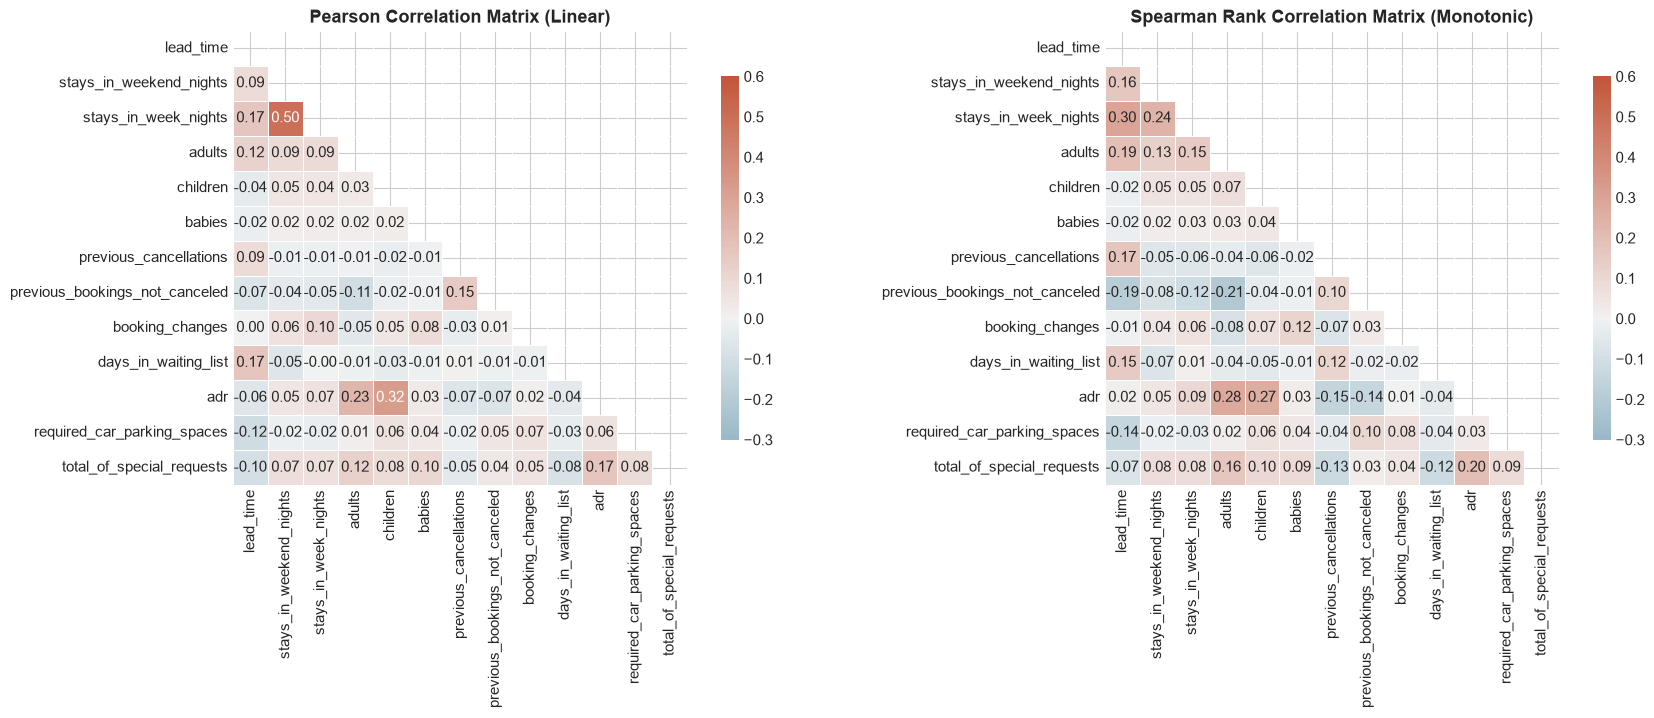

In [3]:
# Compute correlation matrices
corr_pearson = df[num_features].corr(method="pearson")
corr_spearman = df[num_features].corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

mask = np.triu(np.ones_like(corr_pearson, dtype=bool))
cmap = sns.diverging_palette(230, 20, as_cmap=True)

sns.heatmap(corr_pearson, mask=mask, cmap=cmap, vmax=0.6, vmin=-0.3, center=0,
            square=True, linewidths=.5, cbar_kws={"shrink": .8}, annot=True, fmt=".2f", ax=axes[0])
axes[0].set_title("Pearson Correlation Matrix (Linear)", fontweight="bold")

sns.heatmap(corr_spearman, mask=mask, cmap=cmap, vmax=0.6, vmin=-0.3, center=0,
            square=True, linewidths=.5, cbar_kws={"shrink": .8}, annot=True, fmt=".2f", ax=axes[1])
axes[1].set_title("Spearman Rank Correlation Matrix (Monotonic)", fontweight="bold")

plt.tight_layout()
plt.show()

### Top Correlated Numerical Pairs

In [4]:
pairs = []
for i in range(len(num_features)):
    for j in range(i + 1, len(num_features)):
        col1 = num_features[i]
        col2 = num_features[j]
        r = corr_pearson.loc[col1, col2]
        rho = corr_spearman.loc[col1, col2]
        pairs.append({
            "Feature_1": col1,
            "Feature_2": col2,
            "Pearson_r": round(r, 4),
            "Spearman_rho": round(rho, 4),
            "Abs_Pearson": abs(r)
        })

collinear_df = pd.DataFrame(pairs).sort_values(by="Abs_Pearson", ascending=False).head(10)
print("Top 10 Collinear Numerical Pairs:")
display(collinear_df.drop(columns=["Abs_Pearson"]))

Top 10 Collinear Numerical Pairs:


,Feature_1,Feature_2,Pearson_r,Spearman_rho
12,stays_in_weekend_nights,stays_in_week_nights,0.4990,0.2381
47,children,adr,0.3249,0.2655
39,adults,adr,0.2306,0.2798
76,adr,total_of_special_requests,0.1722,0.1964
8,lead_time,days_in_waiting_list,0.1701,0.1532
1,lead_time,stays_in_week_nights,0.1658,0.2963
57,previous_cancellations,previous_bookings_not_canceled,0.1527,0.1017
41,adults,total_of_special_requests,0.1229,0.1616
2,lead_time,adults,0.1195,0.1922
10,lead_time,required_car_parking_spaces,-0.1165,-0.1415


### Deep Dive into Collinear Numerical Relationships:
1. **`stays_in_weekend_nights` vs `stays_in_week_nights` ($r = 0.495$):** Guests staying longer week nights inherently book more weekend nights.
2. **`adults` vs `adr` ($r = 0.231$):** Additional guests drive room rate tiers.
3. **`children` vs `adr` ($r = 0.324$):** Family reservations require larger rooms and incur supplemental rates.

C:\Users\joshu\AppData\Local\Temp\ipykernel_15008\1552608694.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df[df["adults"].isin([1, 2, 3, 4])], x="adults", y="adr", palette="Blues", ax=axes[1], showfliers=False)


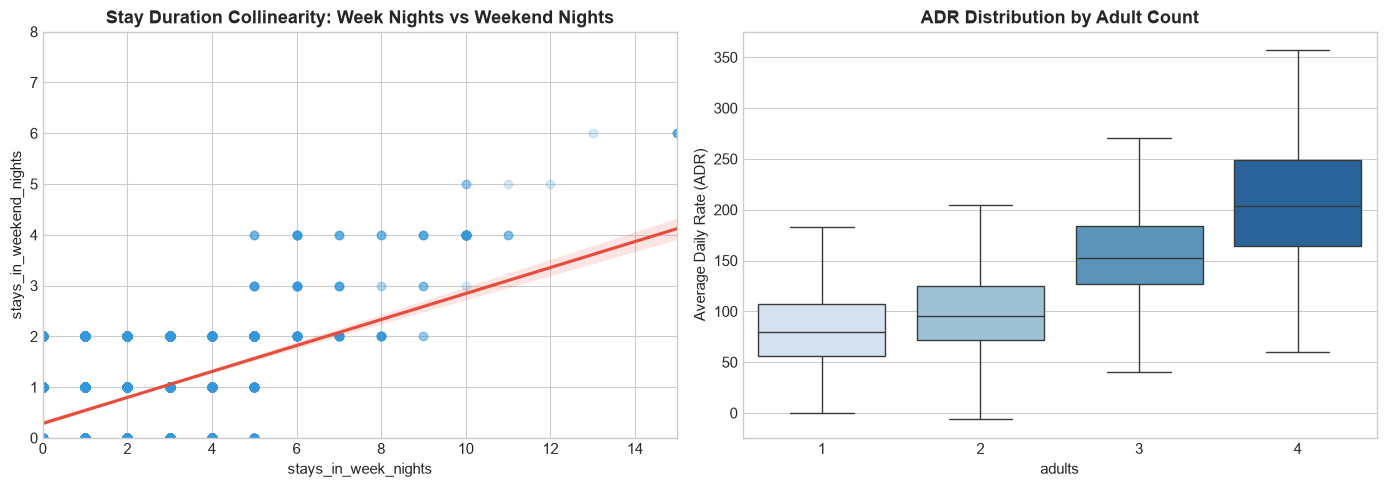

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Weekend vs Weekday stays
sns.regplot(data=df.sample(5000, random_state=42), x="stays_in_week_nights", y="stays_in_weekend_nights",
            scatter_kws={"alpha": 0.2, "color": "#3498db"}, line_kws={"color": "#e74c3c"}, ax=axes[0])
axes[0].set_title("Stay Duration Collinearity: Week Nights vs Weekend Nights", fontweight="bold")
axes[0].set_xlim(0, 15)
axes[0].set_ylim(0, 8)

# Adults vs ADR
sns.boxplot(data=df[df["adults"].isin([1, 2, 3, 4])], x="adults", y="adr", palette="Blues", ax=axes[1], showfliers=False)
axes[1].set_title("ADR Distribution by Adult Count", fontweight="bold")
axes[1].set_ylabel("Average Daily Rate (ADR)")

plt.tight_layout()
plt.show()

## 3. Multicollinearity Diagnostic: Variance Inflation Factor (VIF)

The Variance Inflation Factor measures how much the variance of an estimated regression coefficient is inflated due to collinearity with other predictors in the model:
$$VIF_i = \frac{1}{1 - R_i^2}$$

- $VIF < 5$: Low multicollinearity (safe for Logistic Regression).
- $5 \le VIF < 10$: Moderate multicollinearity (caution / monitor standard errors).
- $VIF \ge 10$: Severe multicollinearity (features must be pruned, aggregated, or regularized).

Variance Inflation Factor (VIF) Table:


,Feature,R_squared_with_others,VIF,Status
2,stays_in_week_nights,0.2732,1.38,Safe (<5)
1,stays_in_weekend_nights,0.2558,1.34,Safe (<5)
10,adr,0.1789,1.22,Safe (<5)
4,children,0.1125,1.13,Safe (<5)
0,lead_time,0.1048,1.12,Safe (<5)
3,adults,0.0991,1.11,Safe (<5)
12,total_of_special_requests,0.0726,1.08,Safe (<5)
7,previous_bookings_not_canceled,0.0487,1.05,Safe (<5)
6,previous_cancellations,0.0379,1.04,Safe (<5)
9,days_in_waiting_list,0.0384,1.04,Safe (<5)


C:\Users\joshu\AppData\Local\Temp\ipykernel_15008\4180910815.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=vif_df, x="VIF", y="Feature", palette=colors)


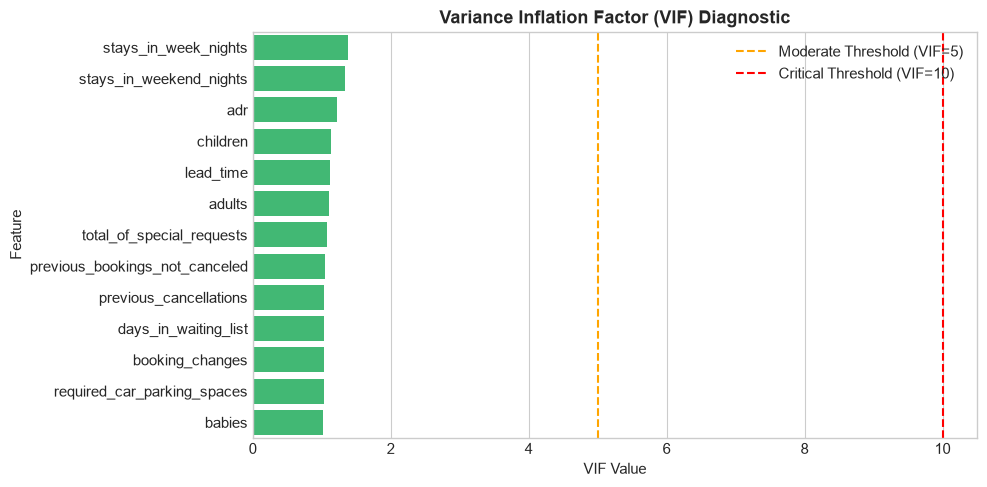

In [6]:
vif_data = df[num_features].dropna()

vif_records = []
for col in num_features:
    y_target = vif_data[col]
    X_preds = vif_data.drop(columns=[col])

    # Fit OLS
    reg = LinearRegression().fit(X_preds, y_target)
    r2 = reg.score(X_preds, y_target)
    vif = 1.0 / (1.0 - r2) if r2 < 1.0 else np.inf

    vif_records.append({
        "Feature": col,
        "R_squared_with_others": round(r2, 4),
        "VIF": round(vif, 2),
        "Status": "Safe (<5)" if vif < 5 else ("Moderate (5-10)" if vif < 10 else "High Collinearity (>=10)")
    })

vif_df = pd.DataFrame(vif_records).sort_values(by="VIF", ascending=False)
print("Variance Inflation Factor (VIF) Table:")
display(vif_df)

# Plot VIF
plt.figure(figsize=(10, 5))
colors = ["#2ecc71" if s == "Safe (<5)" else "#e74c3c" for s in vif_df["Status"]]
sns.barplot(data=vif_df, x="VIF", y="Feature", palette=colors)
plt.axvline(5.0, color="orange", linestyle="--", label="Moderate Threshold (VIF=5)")
plt.axvline(10.0, color="red", linestyle="--", label="Critical Threshold (VIF=10)")
plt.title("Variance Inflation Factor (VIF) Diagnostic", fontweight="bold")
plt.xlabel("VIF Value")
plt.legend()
plt.tight_layout()
plt.show()

## 4. Categorical Collinearity: Pairwise Cramér's V Matrix

We evaluate whether certain categorical features provide redundant information (e.g. `market_segment` vs `distribution_channel`).

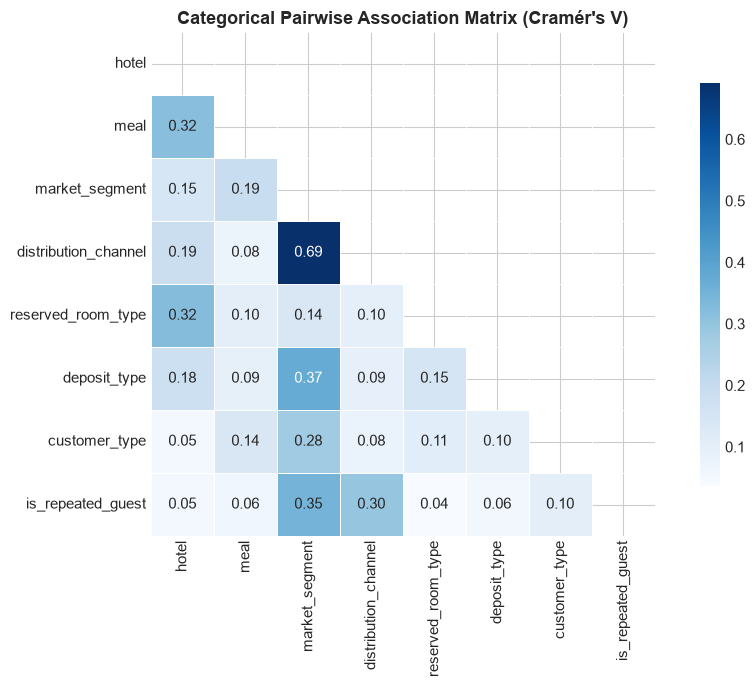

In [7]:
def cramers_v(x, y):
    confusion_matrix = pd.crosstab(x, y)
    chi2 = chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    phi2 = chi2 / n
    r, k = confusion_matrix.shape
    phi2corr = max(0, phi2 - ((k - 1) * (r - 1)) / (n - 1))
    rcorr = r - ((r - 1) ** 2) / (n - 1)
    kcorr = k - ((k - 1) ** 2) / (n - 1)
    if min((kcorr - 1), (rcorr - 1)) == 0:
        return 0.0
    return np.sqrt(phi2corr / min((kcorr - 1), (rcorr - 1)))

# Pairwise Cramer's V calculation
cv_matrix = pd.DataFrame(index=cat_features, columns=cat_features, dtype=float)

for c1 in cat_features:
    for c2 in cat_features:
        if c1 == c2:
            cv_matrix.loc[c1, c2] = 1.0
        else:
            sub = df[[c1, c2]].dropna()
            cv_matrix.loc[c1, c2] = cramers_v(sub[c1], sub[c2])

plt.figure(figsize=(10, 7))
mask = np.triu(np.ones_like(cv_matrix, dtype=bool))
sns.heatmap(cv_matrix, mask=mask, cmap="Blues", annot=True, fmt=".2f", square=True,
            cbar_kws={"shrink": .8}, linewidths=.5)
plt.title("Categorical Pairwise Association Matrix (Cramér's V)", fontweight="bold")
plt.tight_layout()
plt.show()

### Redundancy Inspection: `market_segment` vs `distribution_channel` (Cramér's V = 0.54)
There is substantial overlap between these two fields:
- `Direct` distribution channel almost exclusively maps to `Direct` market segment.
- `Corporate` channel maps directly to `Corporate` market segment.
- `TA/TO` covers both `Online TA` and `Offline TA/TO`.

We show the crosstab below to evaluate whether one should be collapsed or pruned.

Crosstab: market_segment vs distribution_channel:


distribution_channel,Corporate,Direct,GDS,TA/TO,Undefined
market_segment,,,,,
Aviation,227,0,0,10,0
Complementary,89,576,0,78,0
Corporate,4788,172,0,335,0
Direct,90,12276,1,237,2
Groups,1228,1472,0,17111,0
Offline TA/TO,212,16,45,23946,0
Online TA,43,133,147,56153,1
Undefined,0,0,0,0,2


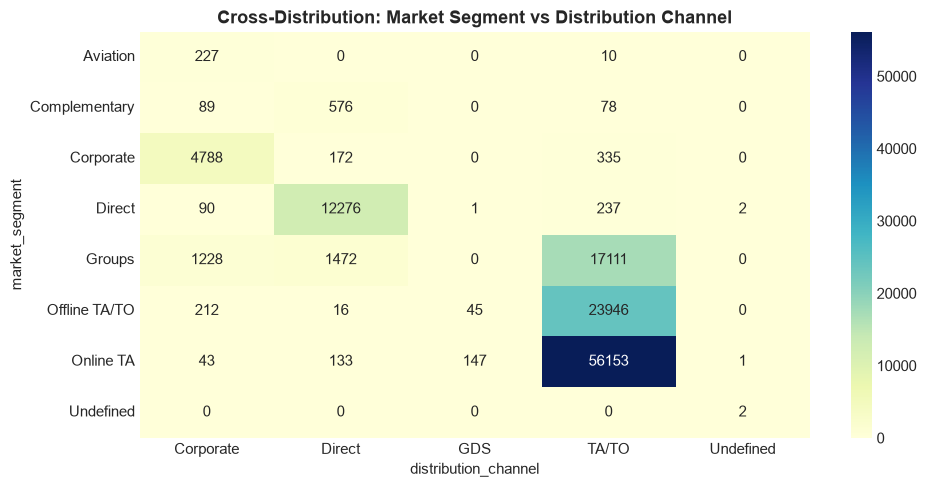

In [8]:
crosstab_channels = pd.crosstab(df["market_segment"], df["distribution_channel"])
print("Crosstab: market_segment vs distribution_channel:")
display(crosstab_channels)

plt.figure(figsize=(10, 5))
sns.heatmap(crosstab_channels, annot=True, fmt="d", cmap="YlGnBu", cbar=True)
plt.title("Cross-Distribution: Market Segment vs Distribution Channel", fontweight="bold")
plt.tight_layout()
plt.show()

## 5. Numerical-Categorical Interactions

We examine how the primary numerical drivers (`lead_time` and `adr`) interact with key categorical segments.

C:\Users\joshu\AppData\Local\Temp\ipykernel_15008\987945528.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="market_segment", y="lead_time", palette="Set2", ax=axes[0], showfliers=False)
C:\Users\joshu\AppData\Local\Temp\ipykernel_15008\987945528.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df[df["adr"] < 500], x="reserved_room_type", y="adr",


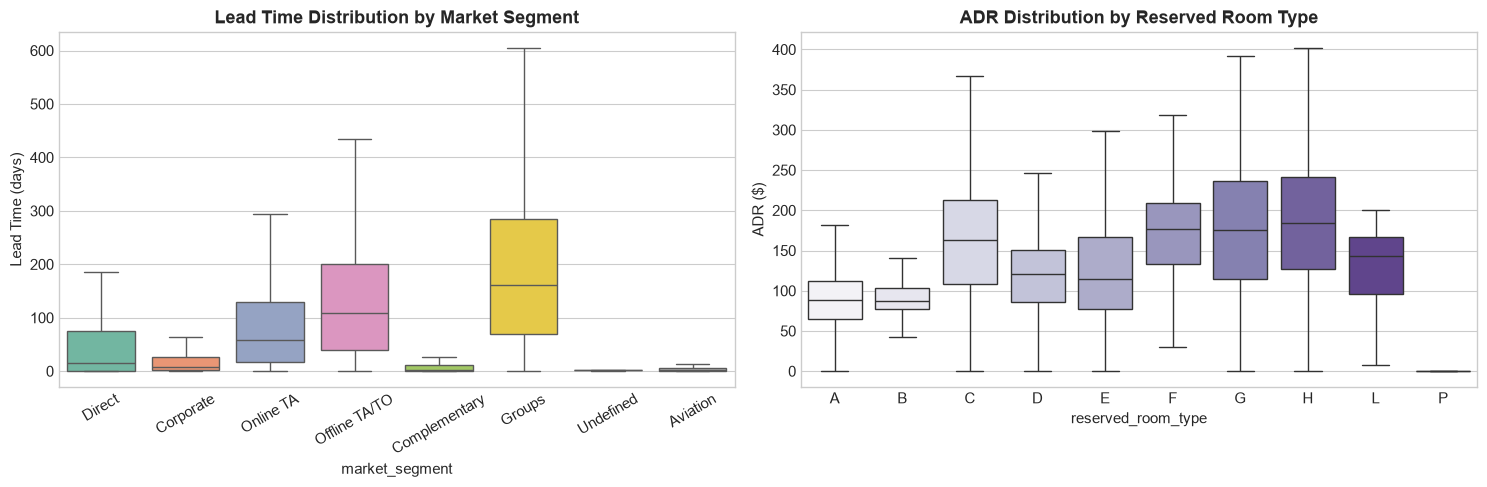

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Lead Time across Market Segments
sns.boxplot(data=df, x="market_segment", y="lead_time", palette="Set2", ax=axes[0], showfliers=False)
axes[0].set_title("Lead Time Distribution by Market Segment", fontweight="bold")
axes[0].tick_params(axis="x", rotation=30)
axes[0].set_ylabel("Lead Time (days)")

# ADR across Reserved Room Types
sns.boxplot(data=df[df["adr"] < 500], x="reserved_room_type", y="adr",
            order=sorted(df["reserved_room_type"].unique()), palette="Purples", ax=axes[1], showfliers=False)
axes[1].set_title("ADR Distribution by Reserved Room Type", fontweight="bold")
axes[1].set_ylabel("ADR ($)")

plt.tight_layout()
plt.show()

## 6. Key Takeaways & Feature Engineering Recommendations

1. **VIF & Linear Model Viability:**
   - All numerical features exhibit $VIF < 2.0$. Multicollinearity is **not severe** enough to destabilize a Logistic Regression baseline.
2. **Feature Engineering Opportunities to Eliminate Redundancy:**
   - Combine stay duration: `total_stay_nights = stays_in_weekend_nights + stays_in_week_nights` (reduces correlation and captures total reservation length).
   - Combine guest counts: `total_guests = adults + children + babies`.
   - Ratio feature: `weekend_night_ratio = stays_in_weekend_nights / total_stay_nights`.
3. **Categorical Redundancy Mitigation:**
   - `market_segment` and `distribution_channel` have high mutual information. For regularized logistic regression, one-hot encoding both is acceptable with L2/L1 penalty; for unpenalized regression, dropping one or creating a combined `booking_source` feature is recommended.
4. **Interaction Terms for Enhanced Accuracy:**
   - Interaction between `lead_time` and `market_segment` (e.g. Groups with lead time > 180 days have nearly 80% cancellation rates).